# Experimentación: Clasificación de CIFAR-10 con CNN

**Evaluación de la Segunda Unidad - Inteligencia Artificial**
Universidad Andina del Cusco - Departamento Académico de Ingeniería de Sistemas

- **Estudiante:** Luidman Zanes
- **Semilla individual:** `30` (`torch.manual_seed(30)` y `np.random.seed(30)`)

Este notebook contiene las pruebas, el análisis exploratorio de datos (EDA) y la visualización de muestras.
Reutiliza el código de `src/dataset.py` y `src/model.py` para que el notebook y los scripts produzcan exactamente los mismos resultados.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))

from dataset import (CIFAR10_MEAN, CIFAR10_STD, CLASSES, SEED, class_distribution, denormalize,
                     get_dataloaders, load_cifar10, print_split_summary, set_seed, show_samples)
from model import CIFAR10CNN, count_parameters, validate_shapes

%matplotlib inline

# Semilla individual (código de matrícula terminado en 30)
set_seed(SEED)
torch.manual_seed(30)
np.random.seed(30)
print("Semilla:", SEED, "| PyTorch:", torch.__version__)

Semilla: 30 | PyTorch: 2.15.0


## 1. Carga del dataset CIFAR-10 (Pregunta 1.1)

Se descarga CIFAR-10 mediante `torchvision.datasets.CIFAR10`. Se crean dos vistas del conjunto de entrenamiento
(una con *data augmentation* y otra limpia para validación) y el conjunto de prueba independiente.

In [2]:
train_aug, train_clean, test_set = load_cifar10()

print("Imágenes de entrenamiento:", len(train_clean))
print("Imágenes de prueba       :", len(test_set))
print("Datos crudos (N, H, W, C):", train_clean.data.shape, train_clean.data.dtype)
print("Clases:", train_clean.classes)

Imágenes de entrenamiento: 50000
Imágenes de prueba       : 10000
Datos crudos (N, H, W, C): (50000, 32, 32, 3) uint8
Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2. Análisis exploratorio (EDA)

### 2.1 Distribución de clases

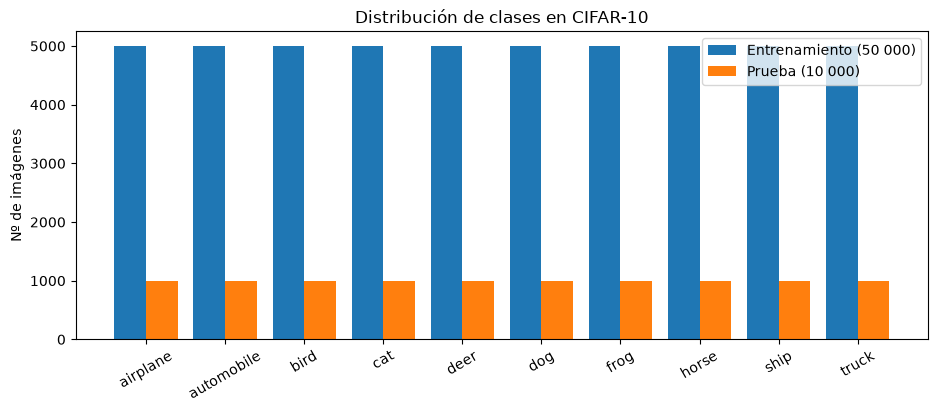

Entrenamiento por clase: {'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}
Prueba por clase       : {'airplane': 1000, 'automobile': 1000, 'bird': 1000, 'cat': 1000, 'deer': 1000, 'dog': 1000, 'frog': 1000, 'horse': 1000, 'ship': 1000, 'truck': 1000}


In [3]:
dist_train = class_distribution(train_clean)
dist_test = class_distribution(test_set)

x = np.arange(len(CLASSES))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, dist_train, width=0.4, label="Entrenamiento (50 000)")
ax.bar(x + 0.2, dist_test, width=0.4, label="Prueba (10 000)")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, rotation=30)
ax.set_ylabel("Nº de imágenes")
ax.set_title("Distribución de clases en CIFAR-10")
ax.legend()
plt.show()

print("Entrenamiento por clase:", dict(zip(CLASSES, dist_train.tolist())))
print("Prueba por clase       :", dict(zip(CLASSES, dist_test.tolist())))

El dataset está perfectamente balanceado (5 000 imágenes por clase en entrenamiento y 1 000 en prueba), por lo que *accuracy* es una métrica representativa.

### 2.2 Estadísticas de los canales RGB

Canal R: media = 0.4914 (usada 0.4914) | std = 0.2470 (usada 0.247)
Canal G: media = 0.4822 (usada 0.4822) | std = 0.2435 (usada 0.2435)
Canal B: media = 0.4465 (usada 0.4465) | std = 0.2616 (usada 0.2616)


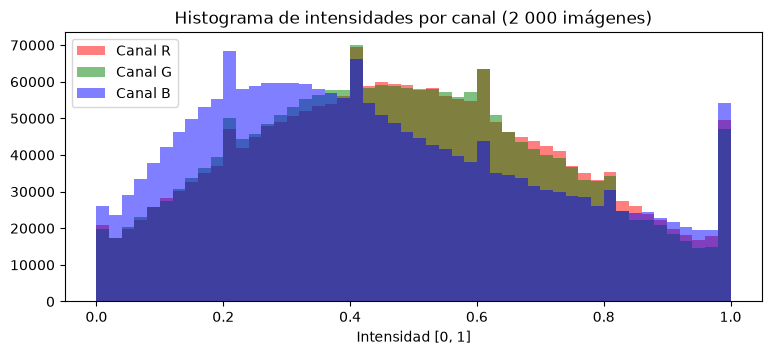

In [4]:
pixels = train_clean.data.astype(np.float32) / 255.0  # (50000, 32, 32, 3)
mean = pixels.mean(axis=(0, 1, 2))
std = pixels.std(axis=(0, 1, 2))
for c, name in enumerate("RGB"):
    print(f"Canal {name}: media = {mean[c]:.4f} (usada {CIFAR10_MEAN[c]}) | std = {std[c]:.4f} (usada {CIFAR10_STD[c]})")

fig, ax = plt.subplots(figsize=(9, 3.5))
for c, color in enumerate(["red", "green", "blue"]):
    ax.hist(pixels[:2000, :, :, c].ravel(), bins=50, alpha=0.5, color=color, label=f"Canal {'RGB'[c]}")
ax.set_title("Histograma de intensidades por canal (2 000 imágenes)")
ax.set_xlabel("Intensidad [0, 1]")
ax.legend()
plt.show()

Los valores calculados coinciden con las constantes usadas en `transforms.Normalize`, lo que justifica la normalización por canal.

## 3. Visualización de muestras con su etiqueta real (Pregunta 1.2)

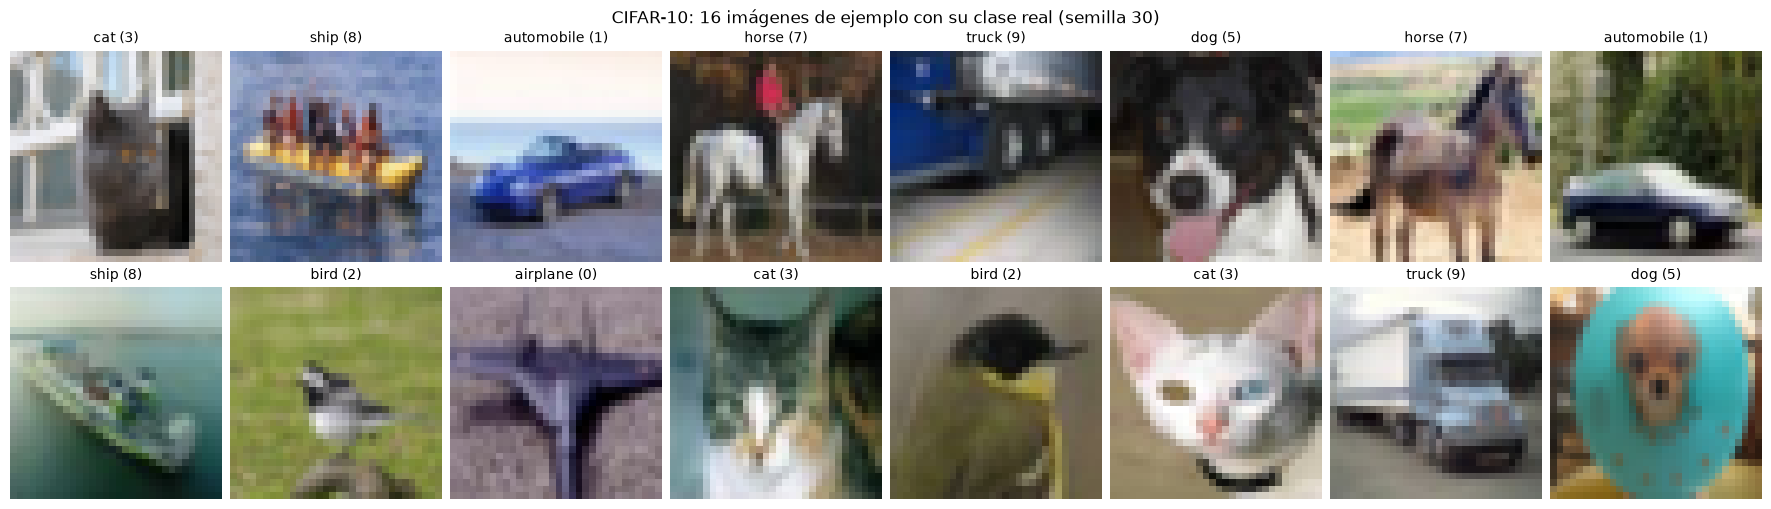

In [5]:
fig = show_samples(train_clean, n=16, cols=8, seed=SEED)

## 4. Pipeline de transformaciones y Data Augmentation (Pregunta 1.3)

- **Entrenamiento:** `RandomCrop(32, padding=4)` → `RandomHorizontalFlip(p=0.5)` → `ToTensor()` → `Normalize(mean, std)`
- **Validación / prueba:** `ToTensor()` → `Normalize(mean, std)`

Se muestra la misma imagen original y 7 versiones aumentadas generadas por el pipeline.

Transformaciones de entrenamiento:
 Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Transformaciones de evaluación:
 Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


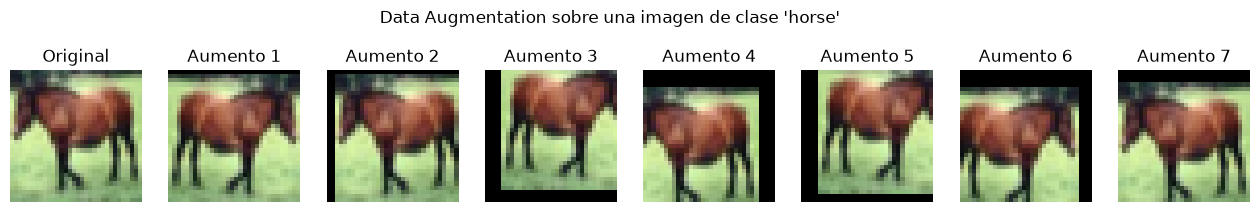

Tensor normalizado (B, C, H, W): (512, 3, 32, 32)
Media por canal tras normalizar: [-0.009 -0.013 -0.012]
Std por canal tras normalizar  : [1.003 0.998 0.987]


In [6]:
print("Transformaciones de entrenamiento:\n", train_aug.transform)
print("\nTransformaciones de evaluación:\n", train_clean.transform)

idx = 7
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
img, label = train_clean[idx]
axes[0].imshow(denormalize(img).permute(1, 2, 0))
axes[0].set_title("Original")
for k in range(1, 8):
    aug_img, _ = train_aug[idx]
    axes[k].imshow(denormalize(aug_img).permute(1, 2, 0))
    axes[k].set_title(f"Aumento {k}")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Data Augmentation sobre una imagen de clase '{CLASSES[label]}'")
plt.show()

batch = torch.stack([train_clean[i][0] for i in range(512)])
print("Tensor normalizado (B, C, H, W):", tuple(batch.shape))
print("Media por canal tras normalizar:", batch.mean(dim=(0, 2, 3)).numpy().round(3))
print("Std por canal tras normalizar  :", batch.std(dim=(0, 2, 3)).numpy().round(3))

## 5. Partición estratificada entrenamiento / validación (Pregunta 1.4)

In [7]:
set_seed(SEED)
train_loader, val_loader, test_loader = get_dataloaders(batch_size=128, num_workers=0)
train_subset, val_subset = train_loader.dataset, val_loader.dataset
print_split_summary(train_subset, val_subset, test_loader.dataset, train_loader)

print("Primeros 10 índices de validación (dependen de la semilla 30):", val_subset.indices[:10].tolist())

Partición estratificada de CIFAR-10 (semilla = 30)
Entrenamiento :  45000 imágenes | shape por imagen: (3, 32, 32)
Validación    :   5000 imágenes | shape por imagen: (3, 32, 32)
Prueba        :  10000 imágenes | shape por imagen: (3, 32, 32)
----------------------------------------------------------------
Distribución por clase (train / val / test):
  0 airplane     4500 /  500 / 1000
  1 automobile   4500 /  500 / 1000
  2 bird         4500 /  500 / 1000
  3 cat          4500 /  500 / 1000
  4 deer         4500 /  500 / 1000
  5 dog          4500 /  500 / 1000
  6 frog         4500 /  500 / 1000
  7 horse        4500 /  500 / 1000
  8 ship         4500 /  500 / 1000
  9 truck        4500 /  500 / 1000
----------------------------------------------------------------
Lote de entrenamiento (B, C, H, W): (128, 3, 32, 32) | etiquetas: (128,)
Primeros 10 índices de validación (dependen de la semilla 30): [34165, 13784, 46463, 44267, 7002, 19027, 40208, 37519, 10916, 11454]


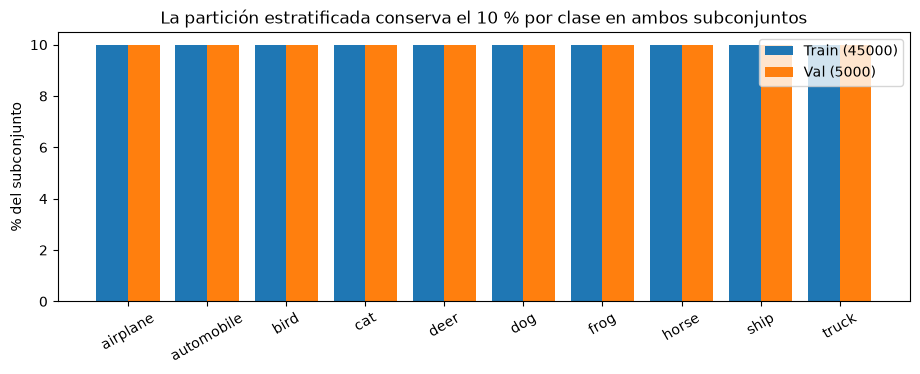

In [8]:
d_tr, d_va = class_distribution(train_subset), class_distribution(val_subset)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - 0.2, d_tr / d_tr.sum() * 100, width=0.4, label=f"Train ({d_tr.sum()})")
ax.bar(x + 0.2, d_va / d_va.sum() * 100, width=0.4, label=f"Val ({d_va.sum()})")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES, rotation=30)
ax.set_ylabel("% del subconjunto")
ax.set_title("La partición estratificada conserva el 10 % por clase en ambos subconjuntos")
ax.legend()
plt.show()
assert (d_va == 500).all() and (d_tr == 4500).all()

## 6. Validación de la arquitectura y del flujo de tensores 4D (Pregunta 3)

In [9]:
torch.manual_seed(SEED)
model = CIFAR10CNN()
print(model)
print(f"\nParámetros entrenables: {count_parameters(model):,}\n")
_ = validate_shapes(model, batch_size=8)

CIFAR10CNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout(p=0.1, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  

In [10]:
# Prueba con un lote REAL del DataLoader (B = 128)
images, labels = next(iter(train_loader))
print("Lote real:", tuple(images.shape), "->")
with torch.no_grad():
    logits = model.eval()(images, verbose=True)
assert logits.shape == (images.size(0), 10)

Lote real: (128, 3, 32, 32) ->
  Entrada                     -> (128, 3, 32, 32)
  Bloque conv 1               -> (128, 32, 16, 16)
  Bloque conv 2               -> (128, 64, 8, 8)
  Bloque conv 3               -> (128, 128, 4, 4)
  Flatten                     -> (128, 2048)
  Linear 1 + ReLU + Dropout   -> (128, 256)
  Linear 2 (logits)           -> (128, 10)


## 7. Prueba de sanidad del entrenamiento

Antes del entrenamiento completo se verifica que el modelo, `CrossEntropyLoss` y `Adam` están bien conectados:
la red debe ser capaz de memorizar (sobreajustar) un único lote pequeño. Si la pérdida no baja, hay un error en el pipeline.

Loss inicial = 2.3605 (≈ ln(10) = 2.3026) | Loss final = 0.0095 | Acc en el lote = 100.0%


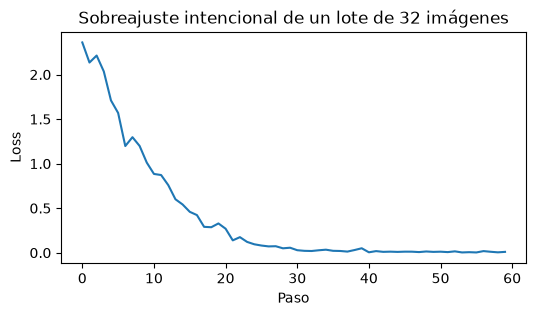

In [11]:
torch.manual_seed(SEED)
probe = CIFAR10CNN()
probe.train()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(probe.parameters(), lr=1e-3)
xb, yb = images[:32], labels[:32]

losses = []
for step in range(60):
    optimizer.zero_grad()
    loss = criterion(probe(xb), yb)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

probe.eval()
with torch.no_grad():
    acc = (probe(xb).argmax(1) == yb).float().mean().item() * 100
print(f"Loss inicial = {losses[0]:.4f} (≈ ln(10) = {np.log(10):.4f}) | Loss final = {losses[-1]:.4f} | Acc en el lote = {acc:.1f}%")
plt.figure(figsize=(6, 3))
plt.plot(losses)
plt.title("Sobreajuste intencional de un lote de 32 imágenes")
plt.xlabel("Paso")
plt.ylabel("Loss")
plt.show()
assert losses[-1] < losses[0] * 0.2

## 8. Resultados del entrenamiento completo (Pregunta 4)

El entrenamiento completo (30 épocas) se ejecuta con `python src/train.py`, que guarda las figuras en `outputs/`.
A continuación se muestran los artefactos generados con la semilla 30. El análisis crítico está en el `README.md`.

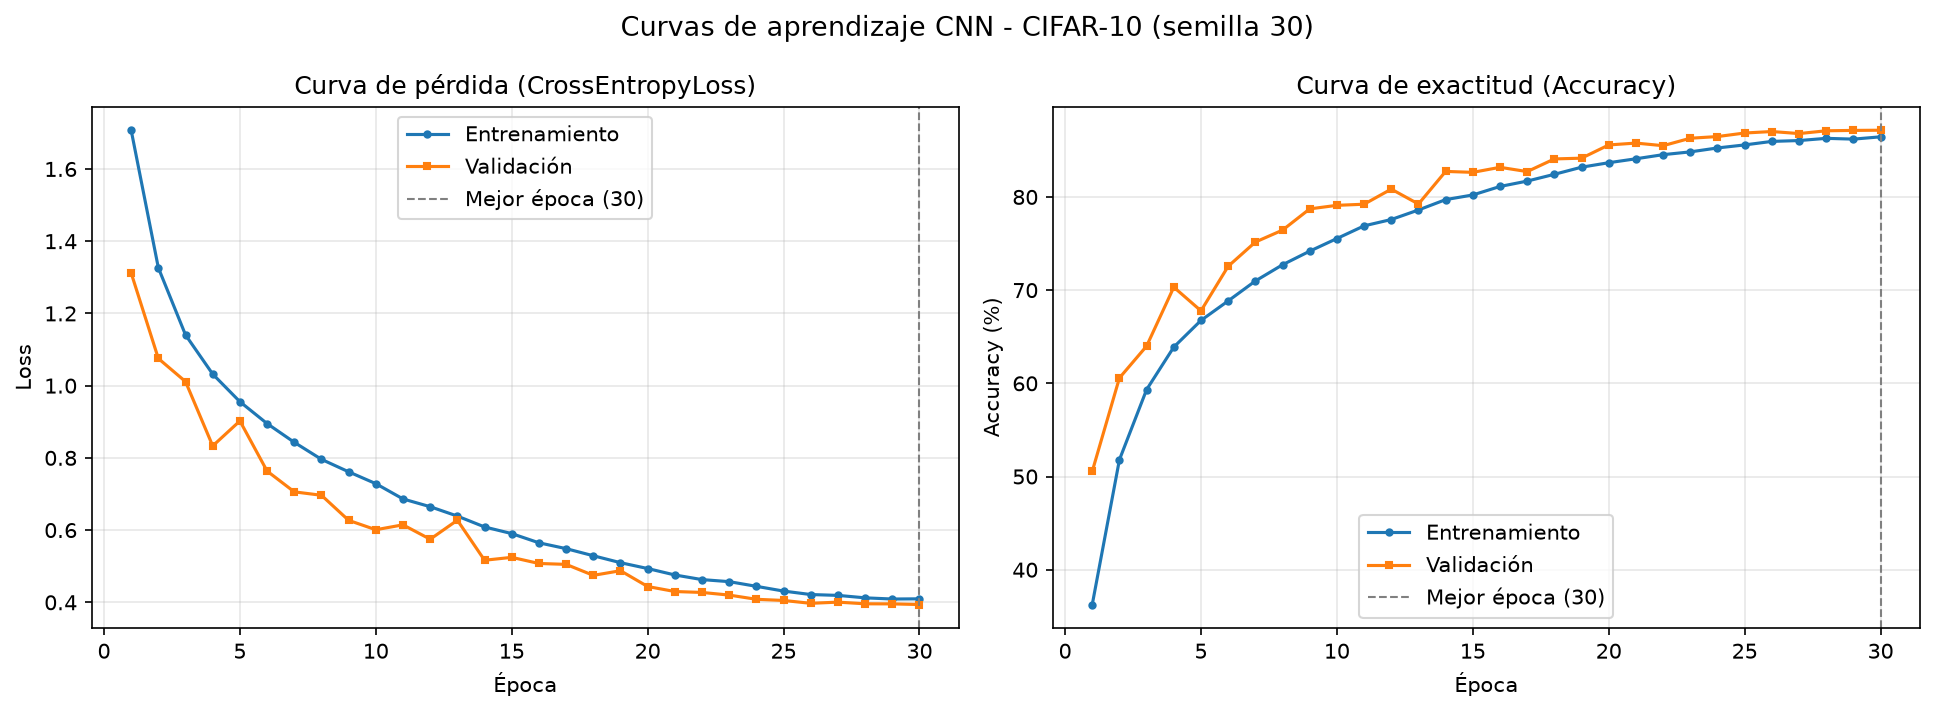

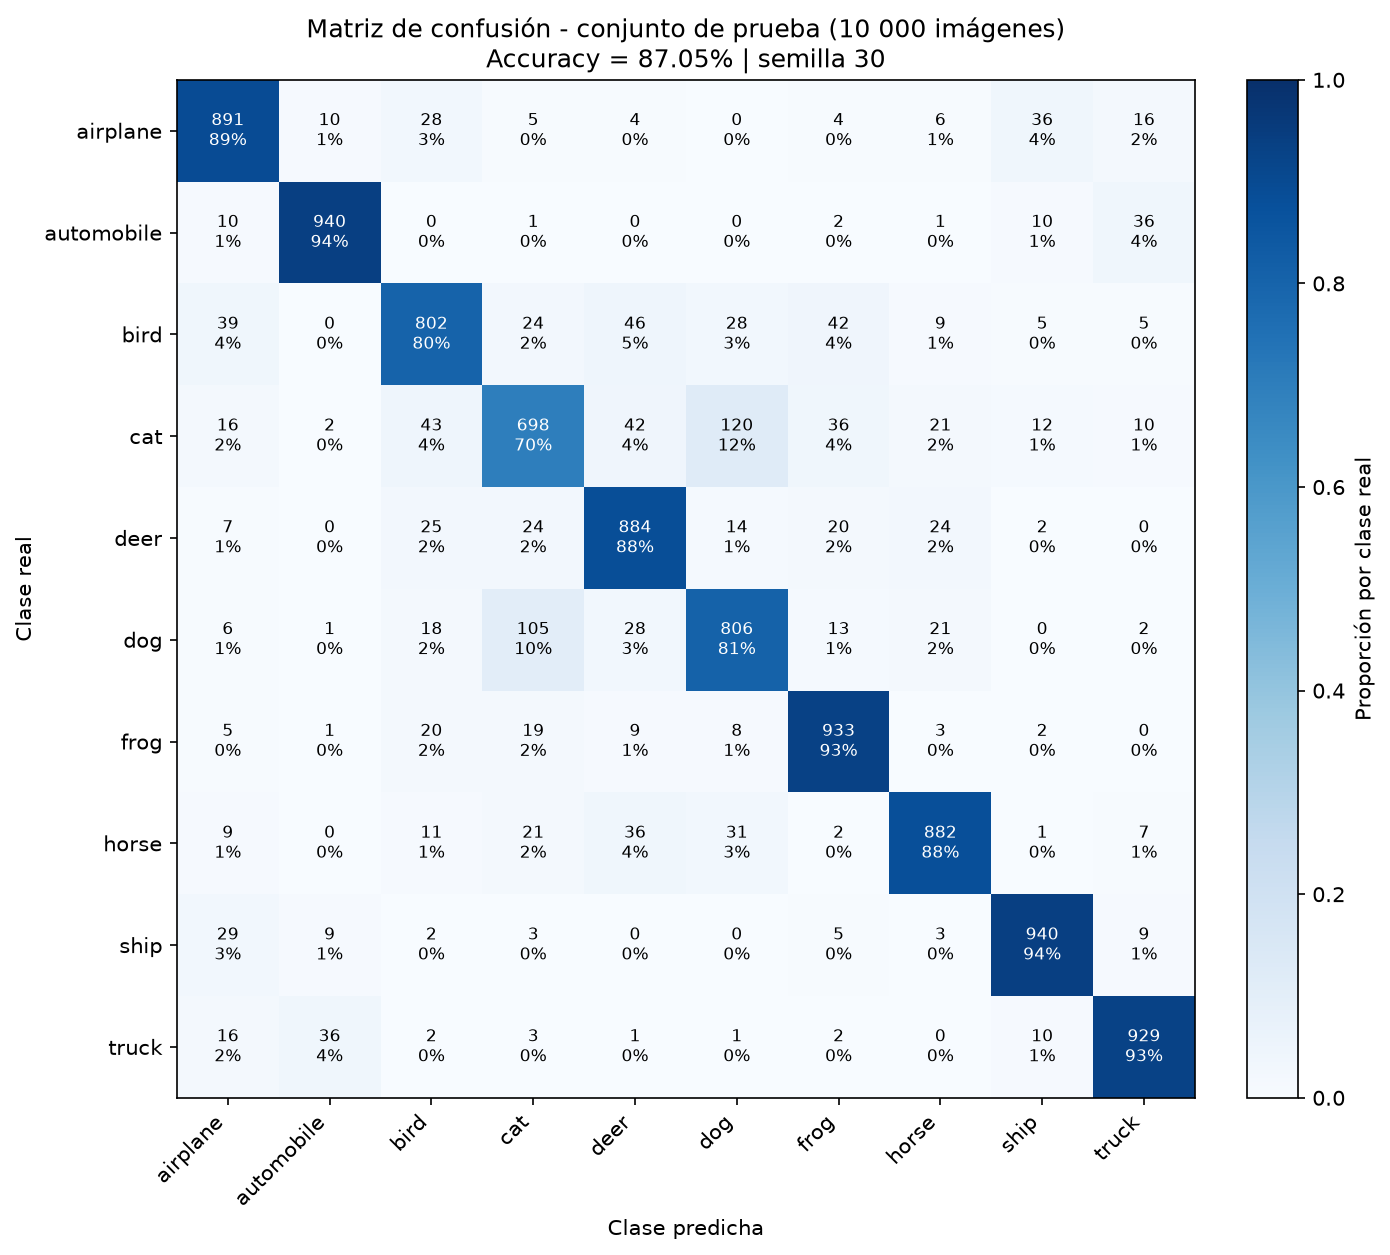

In [12]:
from IPython.display import Image, display

display(Image(filename=os.path.join("..", "outputs", "loss_accuracy.png")))
display(Image(filename=os.path.join("..", "outputs", "confusion_matrix.png")))